In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We propose a new method for training deep neur...,0.3643,0.0900,0.1924,0.8675,0.8158,0.8409,2,8,8,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,Convolutional neural networks (CNNs) have achi...,0.3609,0.0907,0.2055,0.8754,0.8291,0.8516,2,8,8,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,We present a new approach to the specification...,0.3473,0.0727,0.1916,0.8625,0.8587,0.8606,3,9,9,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


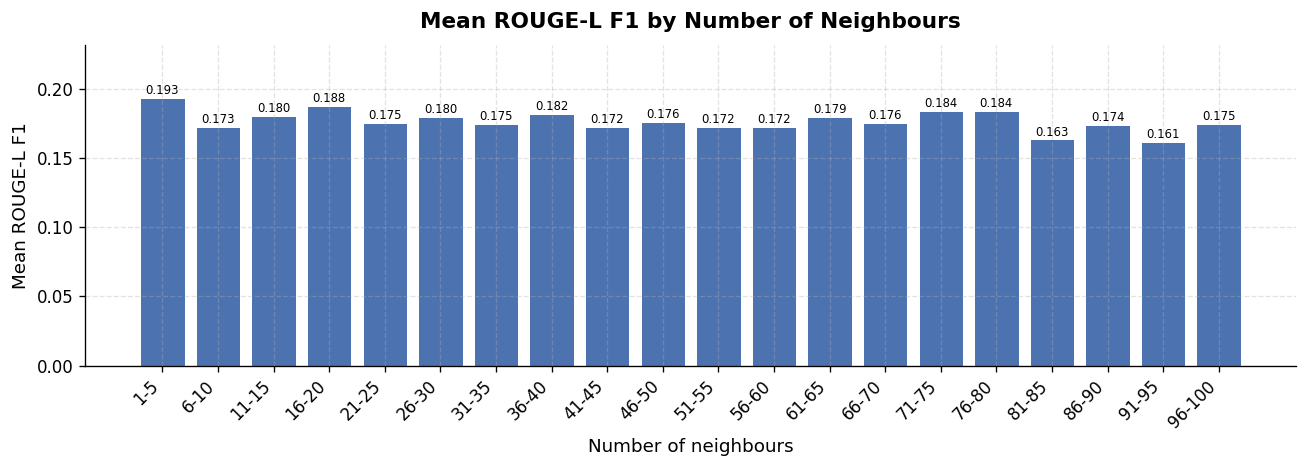

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

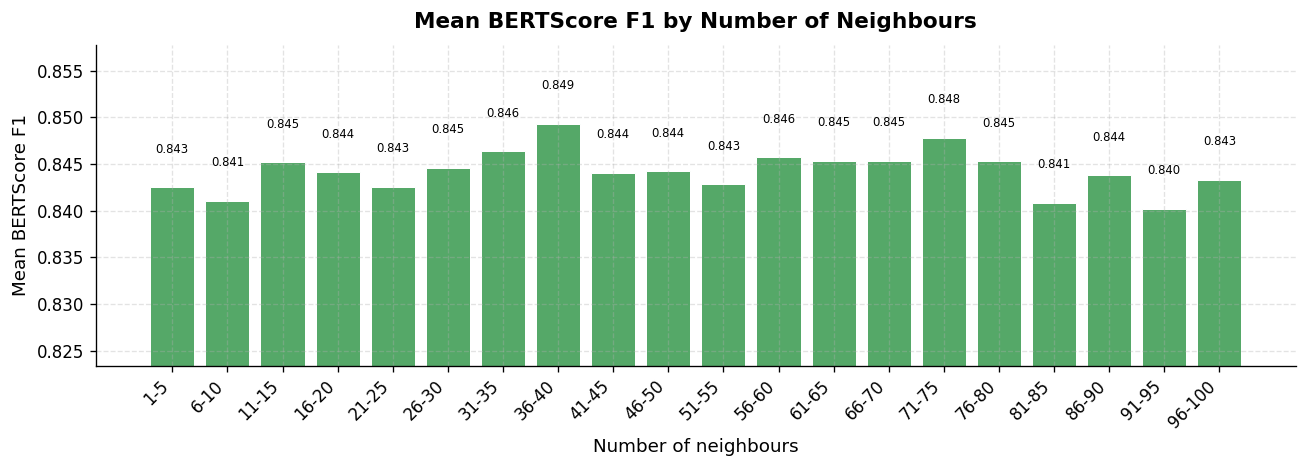

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

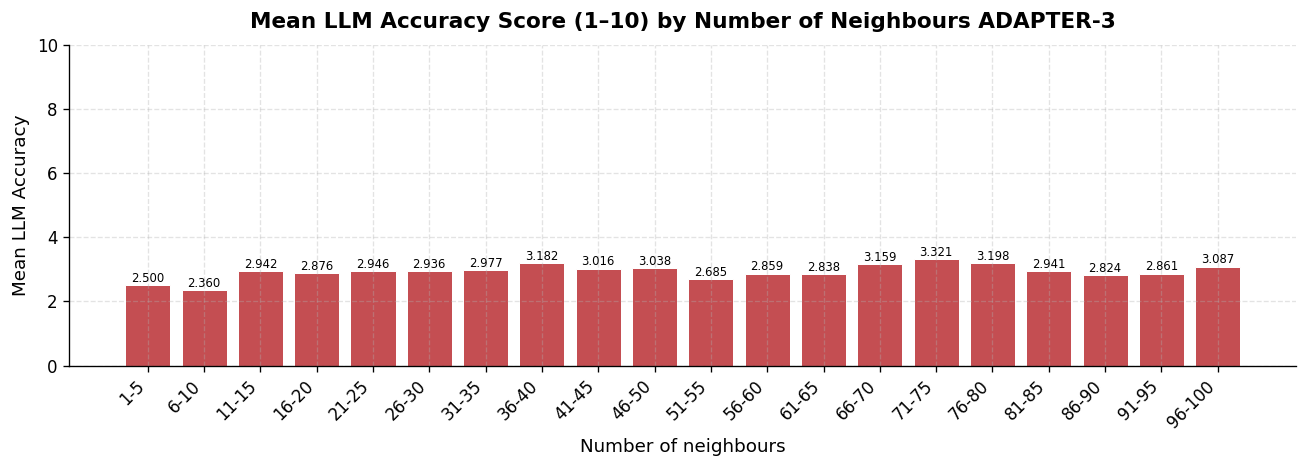

2.942857142857143
3.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

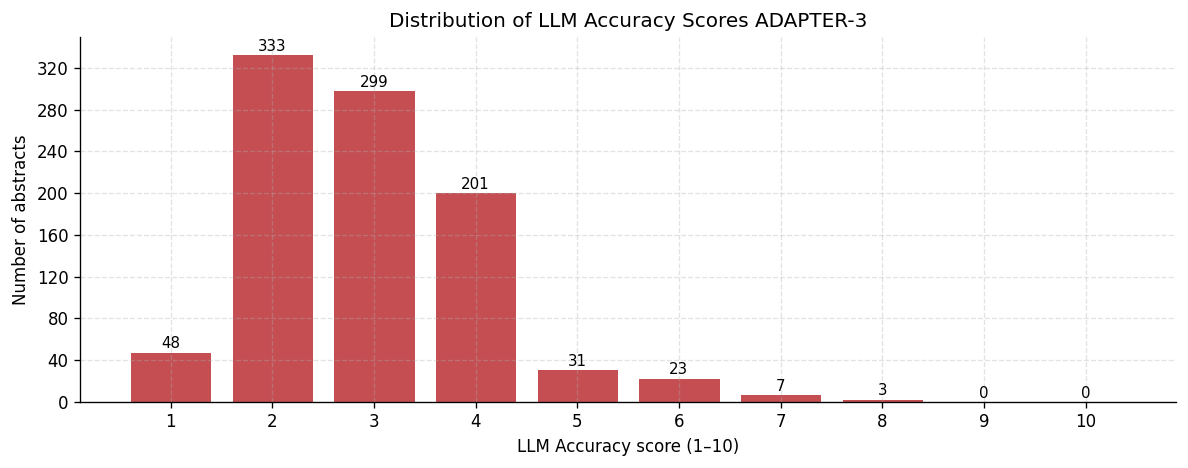

llm_accuracy
1      48
2     333
3     299
4     201
5      31
6      23
7       7
8       3
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

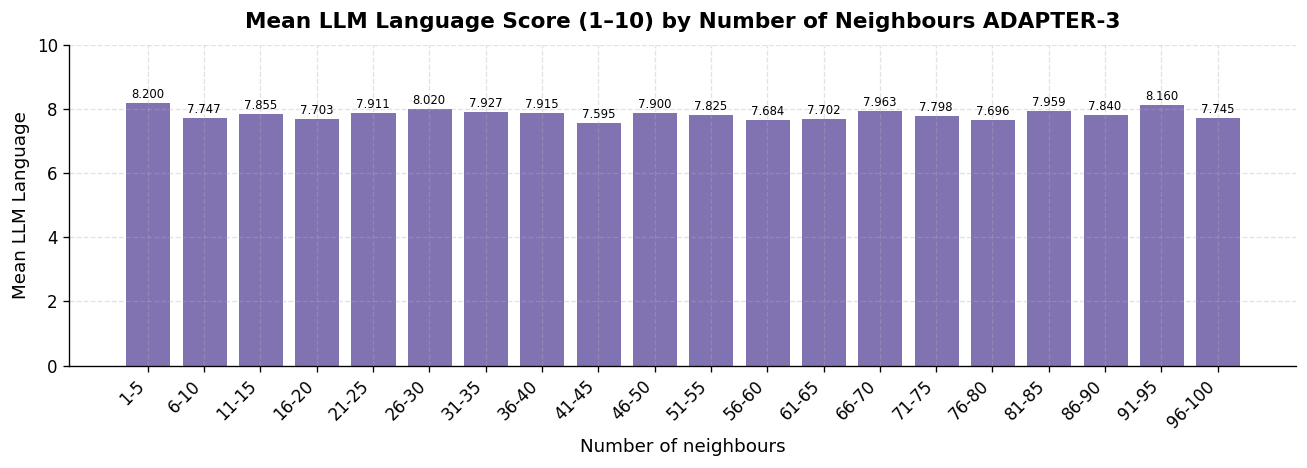

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

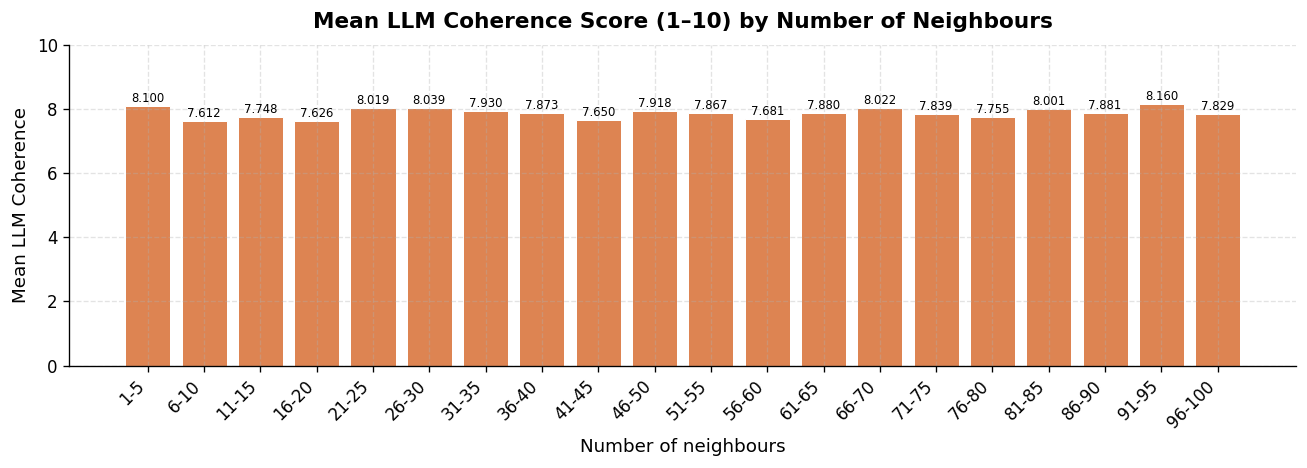

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

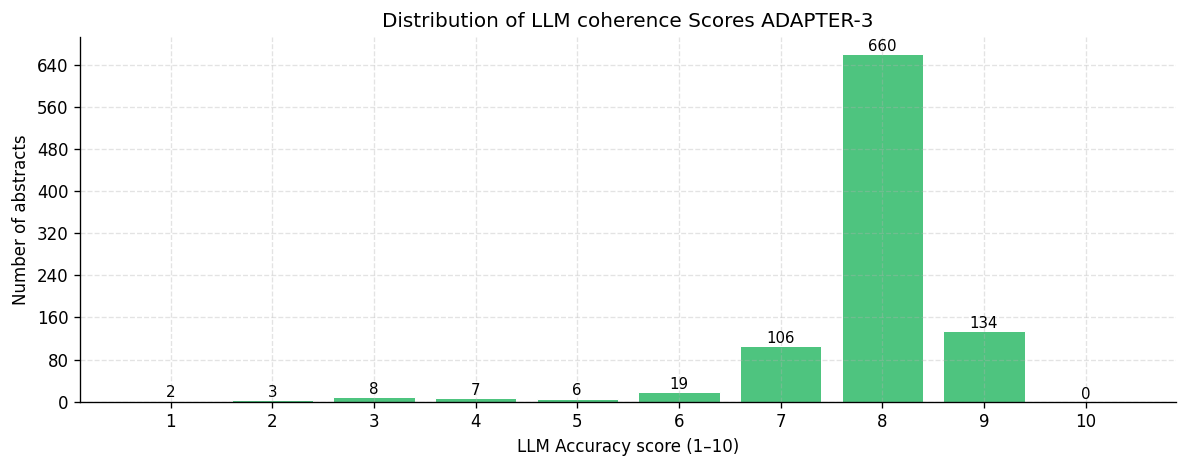

llm_coherence
1       2
2       3
3       8
4       7
5       6
6      19
7     106
8     660
9     134
10      0
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 5 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      2.9429
Mean llm_accuracy (excluding 1,2): 2.9511


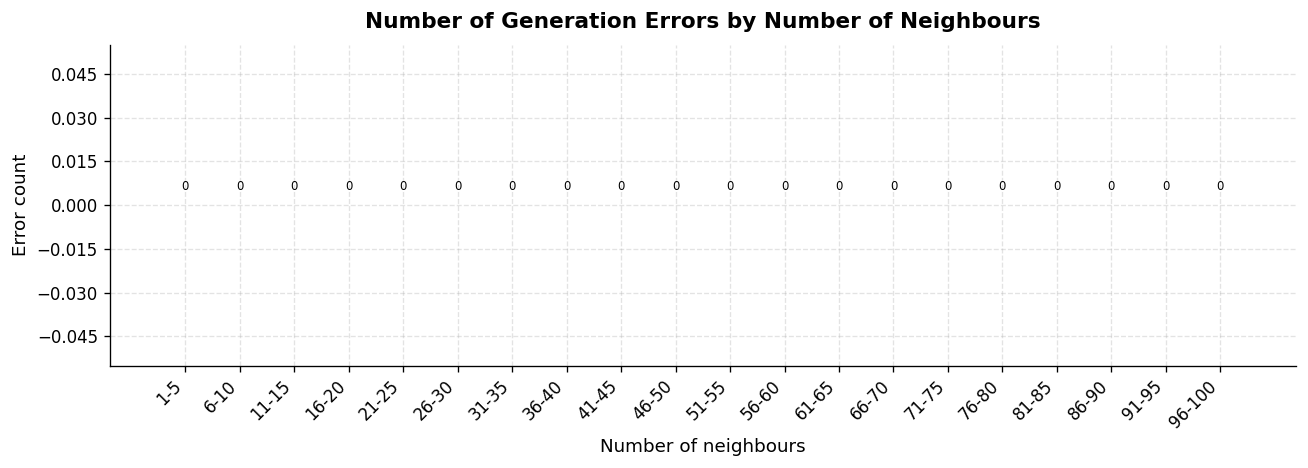

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_56710/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,56958,"Ortega Hypothesis considers masses, i.e., a large number of average people who are not specially qualified as being instrumental in any system's progress. This hypothesis has been reasonably examined in the scientific domain where it has been supported by a few works while refuted by many others, resulting in no clear consensus. While the hypothesis has only been explored in the scientific domain so far, it has hardly been examined in other fields. Given the large-scale collaboration facilitated by the modern Q&A portals where a crowd with a diverse skill-set contributes, an investigation of this hypothesis becomes necessary for informed policy-making. In this work, we investigate the research question inspired by Ortega Hypothesis in StackOverflow where we examine the contribution made by masses and check whether the system may continue to function well even in their absence. The results point towards the importance of masses in Q&A portals for the little but useful contribution that they provide. The insights obtained from the study may help in devising informed incentivization policies enabling better utilization of the potential of the users.","The Wikipedia community is a large and complex social network. In this paper, we present a new approach to the analysis of the Wikipedia community. We use a social network analysis approach to study the Wikipedia community and its evolution over time. We use the Wikipedia community as a case study to demonstrate the usefulness of our approach. We use the Wikipedia data set to study the evolution of the Wikipedia community and to identify the factors that influence the evolution of the Wikipedia social network. We use the Wikipedia social network to study the evolution of Wikipedia and to identify the factors influencing the evolution of Wikipedia. We use the Wikipedia network to study the evolution and the factors influencing the evolution and the factors that influence the Wikipedia community. We also use the Wikipedia network to identify the factors that are influencing the evolution of the Wikipedia network. We use the network to study the evolution, the factors influencing the evolution, and the factors that influence Wikipedia. We use the network and the factors influencing the network to study the factors influencing the evolution. We use the network, the factors influencing the network, and the factors influencing the factors influencing the network. We use the factors influencing the network and the factors that influence these factors to study the factors influencing Wikipedia. We use the factors that influence the network and the factors.",1
1,96460,"We present a new open-source torque-controlled legged robot system, with a low cost and low complexity actuator module at its core. It consists of a low-weight high torque brushless DC motor and a low gear ratio transmission suitable for impedance and force control. We also present a novel foot contact sensor suitable for legged locomotion with hard impacts. A 2.2 kg quadruped robot with a large range of motion is assembled from 8 identical actuator modules and 4 lower legs with foot contact sensors. To the best of our knowledge, it is the most lightest force-controlled quadruped robot. We leverage standard plastic 3D printing and off-the-shelf parts, resulting in light-weight and inexpensive robots, allowing for rapid distribution and duplication within the research community. In order to quantify the capabilities of our design, we systematically measure the achieved impedance at the foot in static and dynamic scenarios. We measured up to 10.8 dimensionless leg stiffness without active damping, which is comparable to the leg stiffness of a running human. Finally, in order to demonstrate the capabilities of our quadruped robot, we propose a novel controller which combines feedforward contact forces computed from a kino-dynamic optimizer with impedance control

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_56710/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,135670,"Exact pattern matching in labeled graphs is the problem of searching paths of a graph $G=(V,E)$ that spell the same string as the given pattern $P[1..m]$. This basic problem can be found at the heart of more complex operations on variation graphs in computational biology, query operations in graph databases, and analysis of heterogeneous networks, where the nodes of some paths must match a sequence of labels or types. In our recent work we described a conditional lower bound stating that the exact pattern matching problem in labeled graphs cannot be solved in less than quadratic time, namely, $O(|E|^{1 - \epsilon} \, m)$ time or $O(|E| \, m^{1 - \epsilon})$ time for any constant $\epsilon>0$, unless the Strong Exponential Time Hypothesis (SETH) is false. The result holds even if node labels and pattern $P$ are drawn from a binary alphabet, and $G$ is restricted to undirected graphs of maximum degree three or directed acyclic graphs of maximum sum of indegree and outdegree three. It was left open what happens on undirected graphs of maximum degree two, i.e., when the pattern can have a zig-zag match in a (cyclic) bidirectional string. Also, the reduction created a non-determistic directed acyclic graph, and it was left open if determinism would make the problem easier. In this work, we show through the Orthogonal Vectors hypothesis (OV) that the same conditional lower bound holds even for these restricted cases.",We study the problem of finding a shortest common supersequence (SCS) of a set of strings. We show that the problem of finding an SCS of a set of strings of total length n is in the complexity class FPT when parameterized by the size of the alphabet. We also show that the problem of deciding whether a string is a shortest common supersequence of a set of strings is in the complexity class W[1] when parameterized by the length of the string.,1
1,72862,"Recent work has presented intriguing results examining the knowledge contained in language models (LM) by having the LM fill in the blanks of prompts such as ""Obama is a _ by profession"". These prompts are usually manually created, and quite possibly sub-optimal; another prompt such as ""Obama worked as a _"" may result in more accurately predicting the correct profession. Because of this, given an inappropriate prompt, we might fail to retrieve facts that the LM does know, and thus any given prompt only provides a lower bound estimate of the knowledge contained in an LM. In this paper, we attempt to more accurately estimate the knowledge contained in LMs by automatically discovering better prompts to use in this querying process. Specifically, we propose mining-based and paraphrasing-based methods to automatically generate high-quality and diverse prompts and ensemble methods to combine answers from different prompts. Extensive experiments on the LAMA benchmark for extracting relational knowledge from LMs demonstrate that our methods can improve accuracy from 31.1% to 38.1%, providing a tighter lower bound on what LMs know. We have released the code and the resulting LM Prompt And Query Archive (LPAQA) at this https URL.","We present a novel neural network architecture for the task of answer selection in open-domain question answering. Our model is based on a bidirectional LSTM with attention, which is trained to predict the correct answer from a set of candidate answers. We show that our model outperforms the state-of-the-art on the Microsoft Research Question Answering (MSMARCO) dataset.",1
2,85908,"From just a short glance at a video, we can often tell whether a person's action is intentional or not. Can we train a model to recognize this? We introduce a dataset of in-the-wild videos of unintentional action, as well as a suite of tasks for recognizing, localizing, and anticipating its onset. We train a supervised neural network as a baseline and analyze its performance compared to human consistency

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


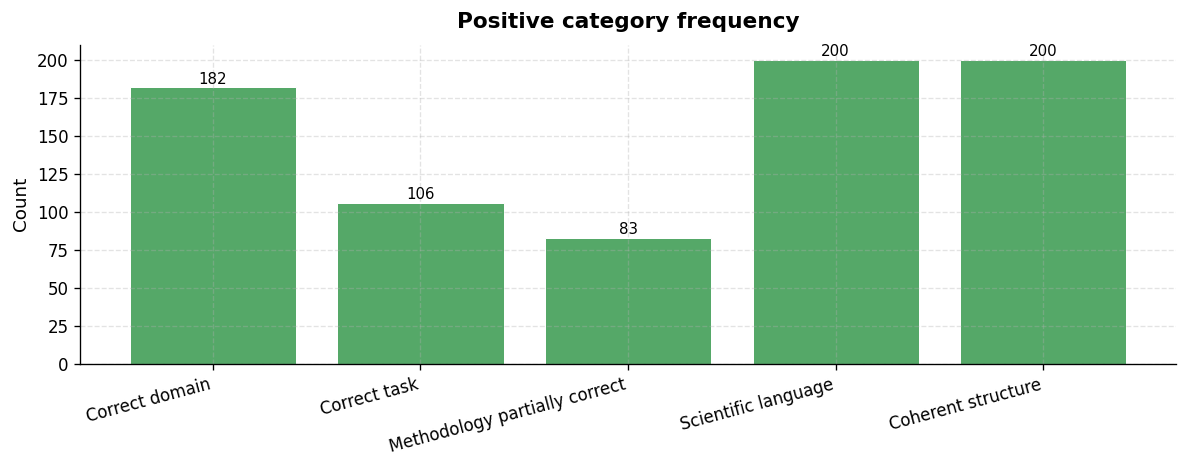

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()